# Sales Variance Analysis Using Python



## 1. Introduction and Project Objective

Sales revenue can change because a company adjusts prices, sells different quantities, gains or loses customers, or sells a different combination of products. Comparing total revenue between two periods reveals the size of the change, but does not explain its components.

This project uses **sales variance analysis** to answer:

> How much of the change in revenue comes from price changes, and how much comes from changes in volume and sales mix?

The analysis compares corresponding periods in two years and separates the revenue change into a **Price Effect** and a **Volume/Mix Effect**. Python will be used to calculate and visualize these effects. Derivatives and integrals will then provide a mathematical interpretation of the standard approach.

Here, *variance* means a difference between periods, rather than the statistical measure of dispersion.



## 2. Scope and Business Classification

Calculations are performed for each **customer-site and product or product sub-family combination**. This matters because customers may pay different prices for the same product. A change in the proportion sold to each customer can alter the overall average price without any individual price changing.

The supplied methodology distinguishes three categories:

- **Base business:** established relationships with more than 12 months of business and comparable information for the periods analyzed.
- **New business (In):** newly started relationships, which remain in this category for a maximum of 11 rolling months under the supplied methodology.
- **Lost business (Out):** relationships confirmed to have ended.

Price effects are calculated for eligible base business. New and lost business contribute to Volume/Mix. Sales history or relationship dates are needed to establish eligibility; sales in both periods alone do not prove the required duration.



## 3. Revenue Model

For one customer–product relationship, sales revenue is:

$$
S = PV + F
$$

where:

- $S$ is sales revenue;
- $P$ is the variable selling price per unit;
- $V$ is the quantity sold;
- $F$ is the total contractual fixed charge for the reporting period.

If there is no fixed charge, $F=0$. When several transactions are combined, the average variable price is volume-weighted:

$$
P = \frac{\text{Total Variable Sales Revenue}}{\text{Total Quantity Sold}}
$$

Fixed charges are kept separate. Otherwise, a lower quantity could increase revenue per unit even when contractual prices have not changed.



## 4. Standard Price and Volume/Mix Decomposition

The decomposition explains the revenue change using two controlled comparisons. For one base-business relationship:

$$
S_1=P_1V_1+F_1,\qquad S_2=P_2V_2+F_2.
$$

Subscripts $1$ and $2$ mean the previous and current periods. Price, quantity, and fixed charges can all change. Comparing $S_1$ with $S_2$ directly tells us the total movement, but does not isolate these drivers.



### 4.1. Create an Intermediate Scenario

First calculate revenue with **current commercial terms and the previous quantity**:

$$
S^*=P_2V_1+F_2.
$$

This hypothetical scenario separates the comparison into two steps:

| Step | What changes? | What stays constant? | Business question |
|---|---|---|---|
| $S_1\rightarrow S^*$ | Variable price and fixed charge | Previous quantity $V_1$ | What would the new terms earn on the old quantity? |
| $S^*\rightarrow S_2$ | Quantity | Current price $P_2$ and charge $F_2$ | What does the quantity change contribute at the new price? |

This sequence follows the supplied methodology: prices are compared on previous-period quantities, and quantity changes are valued at current-period prices. It is a reporting convention, rather than a statement about which commercial change happened first.



### 4.2. Price Effect: Reprice the Original Business

Subtract previous revenue from the intermediate scenario:

$$
\begin{aligned}
\text{Price Effect}&=S^*-S_1\\
&=(P_2V_1+F_2)-(P_1V_1+F_1)\\
&=(P_2-P_1)V_1+(F_2-F_1).
\end{aligned}
$$

The first term measures the unit-price change applied to the original quantity; the second measures the change in the period's fixed charge. Holding quantity constant prevents additional units sold from inflating the pricing contribution.

Using the example in Section 5, the intermediate revenue is $11\times100+220=1{,}320$ euros. Compared with EUR 1,200 previously, this adds EUR 100 from variable price and EUR 20 from fixed charges: a EUR 120 price effect.



### 4.3. Volume/Mix Effect: Move to the Actual Quantity

Subtract the intermediate revenue from current revenue:

$$
\begin{aligned}
\text{Volume/Mix Effect}&=S_2-S^*\\
&=(P_2V_2+F_2)-(P_2V_1+F_2)\\
&=P_2(V_2-V_1).
\end{aligned}
$$

The fixed charge cancels because it is already at its current level. The additional 20 units in the example are valued at EUR 11 each, giving EUR 220. The two comparisons reconcile automatically:

$$
(S^*-S_1)+(S_2-S^*)=S_2-S_1
$$

$$
\boxed{\Delta S=\text{Price Effect}+\text{Volume/Mix Effect}}.
$$



### 4.4. Apply the Calculation Across the Business

Calculate the effects separately for each eligible base-business relationship $i\in B$, then sum:

$$
\text{Price Effect}=\sum_{i\in B}\left[(P_{2i}-P_{1i})V_{1i}+(F_{2i}-F_{1i})\right]
$$

$$
\text{Volume/Mix Effect}=\sum_{i\in B}P_{2i}(V_{2i}-V_{1i})
+\sum_{i\in I}S_{2i}-\sum_{i\in O}S_{1i}.
$$

Here, $I$ and $O$ denote new and lost business. Their contributions are full revenues, including any fixed charges: add current revenue from new business and subtract previous revenue from lost business. Do not invent missing comparison prices.

For a consistently classified dataset, total effects reconcile to the company-wide revenue change. Volume/Mix combines quantity changes, customer/product composition changes, and the price-volume interaction explained in Section 6. It does not separately measure pure mix.



### 4.5. Price-Volume Area Diagram

With **volume on the horizontal axis** and **variable price on the vertical axis**, rectangle area is revenue: units multiplied by euros per unit gives euros. The following diagram uses the example in Section 5, where both price and quantity increase.

- **Previous variable sales:** the blue rectangle has width $V_1=100$ and height $P_1=10$. Its area is $P_1V_1=1{,}000$ euros.
- **Variable price effect:** the teal strip above the blue rectangle has width $V_1$ and height $P_2-P_1$. Its area is $(P_2-P_1)V_1=(11-10)\times100=100$ euros. The sign is current minus previous, so an increase is positive.
- **Volume/Mix effect:** the orange strip to the right has width $V_2-V_1$ and the full current height $P_2$. Its area is $(V_2-V_1)P_2=(120-100)\times11=220$ euros.

The three areas fit together without overlap to form the current variable-sales rectangle: $P_2V_2=1{,}320$ euros. The hatched upper-right corner is the EUR 20 interaction, $(P_2-P_1)(V_2-V_1)$, already included in the orange strip. It must not be counted again as a price contribution.

**Fixed charges sit outside this geometry.** The full price effect adds the EUR 20 fixed-charge increase to the EUR 100 teal area, giving EUR 120. Adding fixed charges to the period revenues gives EUR 1,200 previously and EUR 1,540 currently, consistent with the revenue bridge below.

This diagram also previews the integrals in Section 6: $\int_{P_1}^{P_2}V_1\,dP$ measures the teal area, and $\int_{V_1}^{V_2}P_2\,dV$ measures the orange area. Only their integration direction differs; both results are revenue amounts.


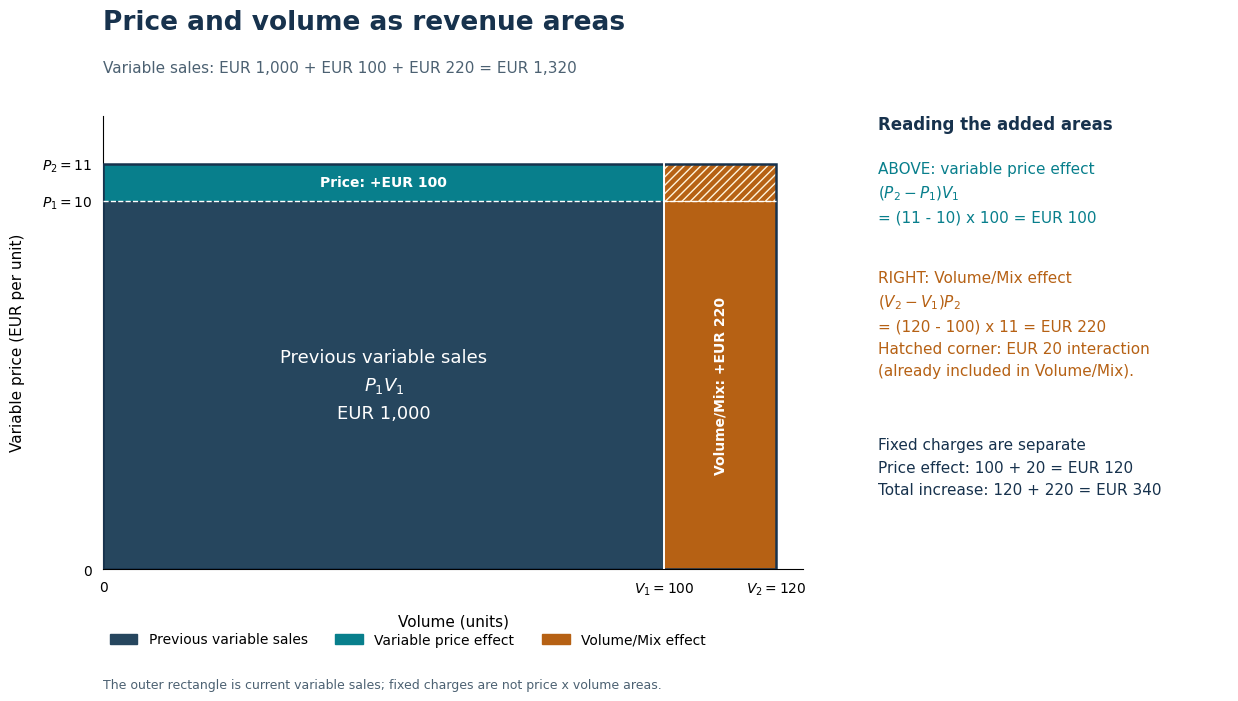

In [1]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Patch

# Same customer-product example; rectangle areas exclude fixed charges.
p1, p2 = 10, 11
v1, v2 = 100, 120
f1, f2 = 200, 220
previous_variable_sales = p1 * v1
current_variable_sales = p2 * v2
variable_price_effect = (p2 - p1) * v1
volume_mix_effect = (v2 - v1) * p2
fixed_charge_effect = f2 - f1
interaction = (p2 - p1) * (v2 - v1)
assert current_variable_sales == previous_variable_sales + variable_price_effect + volume_mix_effect

fig = plt.figure(figsize=(12.5, 7.2), facecolor='white')
ax = fig.add_axes([0.08, 0.19, 0.56, 0.63])
notes = fig.add_axes([0.70, 0.19, 0.28, 0.63])
notes.axis('off')
blue, teal, orange = '#26465E', '#087F8C', '#B66114'

# Three non-overlapping rectangles tile the current variable-sales area.
ax.add_patch(Rectangle((0, 0), v1, p1, facecolor=blue, zorder=2))
ax.add_patch(Rectangle((0, p1), v1, p2 - p1, facecolor=teal, zorder=2))
ax.add_patch(Rectangle((v1, 0), v2 - v1, p2, facecolor=orange, zorder=2))
# The interaction remains part of Volume/Mix; hatching marks it, not a new effect.
ax.add_patch(Rectangle((v1, p1), v2 - v1, p2 - p1,
                       facecolor='none', edgecolor='#FFF4DC', hatch='////',
                       linewidth=0.8, zorder=3))
ax.add_patch(Rectangle((0, 0), v2, p2, facecolor='none',
                       edgecolor='#17324D', linewidth=1.8, zorder=4))
ax.plot([v1, v1], [0, p2], color='white', linewidth=1.4, zorder=4)
ax.plot([0, v2], [p1, p1], color='white', linestyle='--', linewidth=1, zorder=4)
ax.text(v1/2, p1/2,
        f'Previous variable sales\n$P_1 V_1$\nEUR {previous_variable_sales:,.0f}',
        ha='center', va='center', color='white', fontsize=13, linespacing=1.6)
ax.text(v1/2, (p1+p2)/2, f'Price: +EUR {variable_price_effect:,.0f}',
        ha='center', va='center', color='white', fontsize=10, fontweight='bold')
ax.text((v1+v2)/2, p1/2, f'Volume/Mix: +EUR {volume_mix_effect:,.0f}',
        ha='center', va='center', color='white', fontsize=10,
        fontweight='bold', rotation=90)
ax.set_xlim(0, v2*1.04)
ax.set_ylim(0, p2*1.12)
ax.set_xticks([0, v1, v2], ['0', f'$V_1={v1}$', f'$V_2={v2}$'])
ax.set_yticks([0, p1, p2], ['0', f'$P_1={p1}$', f'$P_2={p2}$'])
ax.set_xlabel('Volume (units)', fontsize=11, labelpad=12)
ax.set_ylabel('Variable price (EUR per unit)', fontsize=11, labelpad=12)
ax.tick_params(length=0, pad=8)
for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)

notes.text(0, 1, 'Reading the added areas', fontsize=12,
           fontweight='bold', color='#17324D', va='top')
notes.text(0, 0.90,
           'ABOVE: variable price effect\n'
           r'$(P_2-P_1)V_1$' + '\n'
           f'= ({p2} - {p1}) x {v1} = EUR {variable_price_effect}',
           fontsize=11, color=teal, va='top', linespacing=1.6)
notes.text(0, 0.66,
           'RIGHT: Volume/Mix effect\n'
           r'$(V_2-V_1)P_2$' + '\n'
           f'= ({v2} - {v1}) x {p2} = EUR {volume_mix_effect}\n'
           f'Hatched corner: EUR {interaction} interaction\n'
           '(already included in Volume/Mix).',
           fontsize=11, color=orange, va='top', linespacing=1.6)
notes.text(0, 0.29,
           'Fixed charges are separate\n'
           f'Price effect: {variable_price_effect} + {fixed_charge_effect} = EUR {variable_price_effect + fixed_charge_effect}\n'
           f'Total increase: {variable_price_effect + fixed_charge_effect} + {volume_mix_effect} = EUR {variable_price_effect + fixed_charge_effect + volume_mix_effect}',
           fontsize=11, color='#17324D', va='top', linespacing=1.6)
fig.text(0.08, 0.94, 'Price and volume as revenue areas',
         fontsize=19, fontweight='bold', color='#17324D')
fig.text(0.08, 0.88,
         f'Variable sales: EUR {previous_variable_sales:,.0f} + '
         f'EUR {variable_price_effect:,.0f} + EUR {volume_mix_effect:,.0f}'
         f' = EUR {current_variable_sales:,.0f}',
         fontsize=11, color='#4C6172')
fig.legend(handles=[Patch(color=blue, label='Previous variable sales'),
                    Patch(color=teal, label='Variable price effect'),
                    Patch(color=orange, label='Volume/Mix effect')],
           loc='lower left', bbox_to_anchor=(0.075, 0.065),
           ncol=3, frameon=False, fontsize=10)
fig.text(0.08, 0.025,
         'The outer rectangle is current variable sales; fixed charges are not price x volume areas.',
         fontsize=9, color='#4C6172')
plt.show()


## 5. Worked Example

Consider an established customer site buying the same product in both periods. Its contract contains a variable price per unit and a fixed service charge:

| Measure | Previous period | Current period |
|---|---:|---:|
| Quantity sold | 100 | 120 |
| Variable price per unit | €10 | €11 |
| Total fixed charge | €200 | €220 |
| Sales revenue | €1,200 | €1,540 |

Previous-period revenue is $10\times100+200=1{,}200$ euros. Current-period revenue is $11\times120+220=1{,}540$ euros. The observed change is therefore:

$$
\Delta S=1{,}540-1{,}200=340\text{ euros}
$$



### Step 1: Reprice the Previous Quantity

First ask: **What would revenue have been if the customer had bought the previous quantity under the current prices and fixed charge?**

This creates an intermediate scenario:

$$
S^*=P_2V_1+F_2=11\times100+220=1{,}320\text{ euros}
$$

Compared with the original EUR 1,200, this scenario adds EUR 100 from the EUR 1 per-unit price increase and EUR 20 from the higher fixed charge. Thus:

$$
(11-10)\times100+(220-200)=120\text{ euros}
$$

$$
\text{Price Effect}=S^*-S_1=1{,}320-1{,}200=120\text{ euros}
$$

Using the previous quantity isolates the pricing contribution from the customer's decision to purchase more units.



### Step 2: Move to the Actual Current Quantity

Next ask: **How much additional revenue comes from moving from 100 to 120 units at the current price?**

The additional 20 units generate EUR 11 each. The fixed charge is already at its current level, so it does not change in this step:

$$
11\times(120-100)=220\text{ euros}
$$

The complete bridge is:

| Scenario | Price per unit | Quantity | Fixed charge | Revenue | Change |
|---|---:|---:|---:|---:|---:|
| Previous period | EUR 10 | 100 | EUR 200 | EUR 1,200 | — |
| Previous quantity, current commercial terms | EUR 11 | 100 | EUR 220 | EUR 1,320 | +EUR 120 price effect |
| Current period | EUR 11 | 120 | EUR 220 | EUR 1,540 | +EUR 220 Volume/Mix |

The EUR 340 increase is fully explained: $120+220=340$. In this single-product example, Volume/Mix comes from quantity growth, including its interaction with price. Across many customer–product relationships, the same calculation also captures changes in sales composition.

This is a revenue explanation. The EUR 220 attributed to quantity growth is additional revenue; its profit contribution depends on the costs of supplying those units.



## 6. How Derivatives and Integrals Explain the Methodology

Section 4 gives the exact algebraic calculation. Calculus explains it in two stages: **derivatives identify revenue sensitivity; integrals accumulate that sensitivity over a specified change**. The methodology chooses what is held constant, so it also determines which sensitivities enter each integral.



### 6.1. Derivatives: Identify the Sensitivity

For one relationship, revenue is the function $S(P,V,F)=PV+F$. A partial derivative changes one input while holding the others fixed. For example, increase price by a small amount $h$ while keeping quantity and fixed charge unchanged:

$$
\frac{S(P+h,V,F)-S(P,V,F)}{h}
=\frac{(P+h)V+F-(PV+F)}{h}=V.
$$

Taking the limit as $h$ tends to zero gives $\partial S/\partial P=V$. The business meaning is that the quantity being repriced determines revenue sensitivity to price. The three sensitivities are:

$$
\frac{\partial S}{\partial P}=V,\qquad
\frac{\partial S}{\partial V}=P,\qquad
\frac{\partial S}{\partial F}=1.
$$

| Derivative | Meaning, with other inputs fixed | Application |
|---|---|---|
| $\partial S/\partial P=V$ | Revenue change per unit of price change | At 100 units, a EUR 0.10 per-unit price increase adds EUR 10 |
| $\partial S/\partial V=P$ | Revenue change per additional unit | At EUR 11 per unit, 2 more units add EUR 22 |
| $\partial S/\partial F=1$ | Revenue change per euro of fixed-charge change | A EUR 20 charge increase adds EUR 20 |

The units are consistent: units sold multiplied by euros per unit gives euros of revenue. These sensitivities measure revenue, not profit. Holding quantity fixed also means the price derivative does not predict customer demand after a price increase; that requires a demand model.

Together, the derivatives give the total differential:

$$
dS=V\,dP+P\,dV+dF.
$$

The symbol $d$ describes infinitesimal changes; $\Delta$ describes finite changes between periods. Using the starting sensitivities for an entire finite change can miss the interaction between price and quantity, as shown in Section 6.4.



#### Visualizing a Derivative as the Slope of Revenue

The price-volume diagram in Section 4 puts price and quantity on the axes, so revenue is an **area**. Here, revenue is on the vertical axis and one driver is on the horizontal axis, so its derivative is a **slope**:

$$
\text{Slope}=\frac{\text{Vertical change in revenue}}{\text{Horizontal change in the driver}}.
$$

Read the panels from left to right. They trace the same hypothetical comparison path used by the methodology:

1. **Price panel:** keep quantity at 100 units and the fixed charge at EUR 200. Moving price from EUR 10 to EUR 11 moves revenue from EUR 1,200 to EUR 1,300. The slope is $100/1=100=V_1$. This is why the price derivative equals volume: each EUR 1 per-unit price increase applies to all 100 units.
2. **Fixed-charge panel:** keep price at EUR 11 and quantity at 100. Increasing the charge from EUR 200 to EUR 220 moves revenue from EUR 1,300 to EUR 1,320. The slope is $20/20=1$.
3. **Volume panel:** keep price at EUR 11 and the fixed charge at EUR 220. Moving quantity from 100 to 120 moves revenue from EUR 1,320 to EUR 1,540. The slope is $220/20=11=P_2$, or EUR 11 per additional unit.

The dashed triangles show the **horizontal run** and **vertical rise**. Their ratios are sensitivities; the rises themselves are revenue effects. The first two rises form the EUR 120 price effect, and the third is the EUR 220 Volume/Mix effect.

A derivative is formally the slope as the two points approach each other. In each panel the revenue function is a straight line because the other inputs are fixed. Its slope is constant, so shrinking the triangle leaves the ratio unchanged: the finite-change slope also equals the derivative exactly. If multiple inputs changed together, one such slope would not isolate a partial derivative.

The panels use separate zoomed scales: compare the calculated ratios, not the visual angles. Section 6.2 then explains how integrating these sensitivities recovers the revenue amounts.


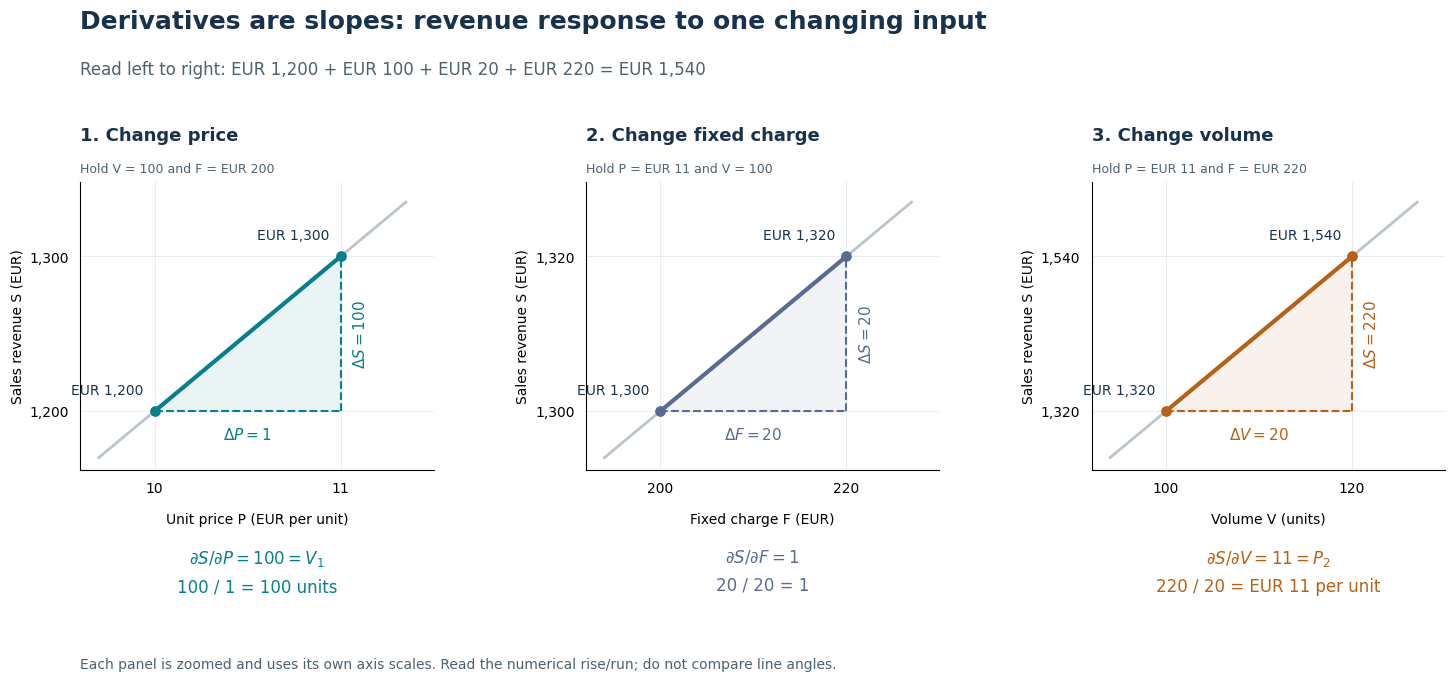

In [3]:
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

p1, p2 = 10, 11
v1, v2 = 100, 120
f1, f2 = 200, 220
# Each panel is a one-variable slice of S = P*V + F.
panels = [
    dict(title='1. Change price', held='Hold V = 100 and F = EUR 200',
         xlabel='Unit price P (EUR per unit)', x0=p1, x1=p2,
         slope=v1, intercept=f1, color='#087F8C',
         dx=r'$\Delta P=1$', dy=r'$\Delta S=100$',
         derivative=r'$\partial S/\partial P=100=V_1$',
         ratio='100 / 1 = 100 units'),
    dict(title='2. Change fixed charge', held='Hold P = EUR 11 and V = 100',
         xlabel='Fixed charge F (EUR)', x0=f1, x1=f2,
         slope=1, intercept=p2*v1, color='#596B91',
         dx=r'$\Delta F=20$', dy=r'$\Delta S=20$',
         derivative=r'$\partial S/\partial F=1$',
         ratio='20 / 20 = 1'),
    dict(title='3. Change volume', held='Hold P = EUR 11 and F = EUR 220',
         xlabel='Volume V (units)', x0=v1, x1=v2,
         slope=p2, intercept=f2, color='#B66114',
         dx=r'$\Delta V=20$', dy=r'$\Delta S=220$',
         derivative=r'$\partial S/\partial V=11=P_2$',
         ratio='220 / 20 = EUR 11 per unit'),
]
fig, axes = plt.subplots(1, 3, figsize=(15, 7.2), facecolor='white')
for ax, panel in zip(axes, panels):
    x0, x1 = panel['x0'], panel['x1']
    m, b = panel['slope'], panel['intercept']
    y0, y1 = m*x0+b, m*x1+b
    dx, dy = x1-x0, y1-y0
    # Straight line: its tangent and secant have the same slope.
    extent = [x0-0.3*dx, x1+0.35*dx]
    ax.plot(extent, [m*x+b for x in extent], color='#BAC5CE', linewidth=2)
    ax.plot([x0, x1], [y0, y1], color=panel['color'], linewidth=3, zorder=3)
    ax.scatter([x0, x1], [y0, y1], s=45, color=panel['color'], zorder=4)
    # Slope triangle: horizontal run, then vertical rise.
    ax.fill([x0, x1, x1], [y0, y0, y1], color=panel['color'], alpha=0.08)
    ax.plot([x0, x1], [y0, y0], '--', color=panel['color'], linewidth=1.5)
    ax.plot([x1, x1], [y0, y1], '--', color=panel['color'], linewidth=1.5)
    ax.text((x0+x1)/2, y0-0.10*dy, panel['dx'],
            ha='center', va='top', fontsize=11, color=panel['color'])
    ax.text(x1+0.06*dx, (y0+y1)/2, panel['dy'],
            ha='left', va='center', rotation=90, fontsize=11, color=panel['color'])
    ax.annotate(f'EUR {y0:,.0f}', (x0, y0), xytext=(-8, 12),
                textcoords='offset points', ha='right', fontsize=10, color='#17324D')
    ax.annotate(f'EUR {y1:,.0f}', (x1, y1), xytext=(-8, 12),
                textcoords='offset points', ha='right', fontsize=10, color='#17324D')
    ax.set_xlim(x0-0.4*dx, x1+0.5*dx)
    ax.set_ylim(y0-0.38*dy, y1+0.48*dy)
    ax.set_xticks([x0, x1])
    ax.set_yticks([y0, y1])
    ax.yaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))
    ax.set_xlabel(panel['xlabel'], labelpad=12, fontsize=10)
    ax.set_ylabel('Sales revenue S (EUR)', fontsize=10)
    ax.set_title(panel['title'], loc='left', fontsize=13,
                 fontweight='bold', color='#17324D', pad=30)
    ax.text(0, 1.035, panel['held'], transform=ax.transAxes,
            fontsize=9, color='#4C6172')
    ax.text(0.5, -0.27, panel['derivative']+'\n'+panel['ratio'],
            transform=ax.transAxes, ha='center', va='top',
            fontsize=12, color=panel['color'], linespacing=1.7)
    ax.grid(color='#E7EDF1', linewidth=0.7)
    ax.set_axisbelow(True)
    ax.tick_params(length=0, pad=8)
    for side in ['top', 'right']:
        ax.spines[side].set_visible(False)
fig.suptitle('Derivatives are slopes: revenue response to one changing input',
             x=0.065, y=0.96, ha='left', fontsize=18, fontweight='bold', color='#17324D')
fig.text(0.065, 0.87,
         'Read left to right: EUR 1,200 + EUR 100 + EUR 20 + EUR 220 = EUR 1,540',
         fontsize=12, color='#4C6172')
fig.text(0.065, 0.045,
         'Each panel is zoomed and uses its own axis scales. Read the numerical rise/run; do not compare line angles.',
         fontsize=10, color='#4C6172')
fig.subplots_adjust(left=0.065, right=0.975, top=0.72, bottom=0.32, wspace=0.43)
plt.show()


### 6.2. Integrals: Turn Sensitivities into Exact Amounts

A derivative tells us the revenue sensitivity at a point. A definite integral accumulates that sensitivity between starting and ending values. The **fundamental theorem of calculus** connects them: integrating a derivative gives the corresponding function change.

To apply this correctly, first specify what stays constant. During repricing, hold $V=V_1$ and $F=F_1$. The one-variable revenue function becomes $g(P)=PV_1+F_1$, with derivative $g'(P)=V_1$. Therefore:

$$
\int_{P_1}^{P_2}g'(P)\,dP
=g(P_2)-g(P_1)
=V_1(P_2-P_1).
$$

The limits $P_1$ and $P_2$ are the old and new prices. The symbol $dP$ identifies price as the changing variable. The constant $V_1$ enforces the previous-volume convention. The result is precisely the variable-price component in Section 4.

We integrate over price, quantity, or the fixed charge, not over time. These intervals describe controlled comparisons between two observed periods. No continuous record of actual price changes is required.



#### Visualizing an Integral as an Accumulated Revenue Change

In Section 6.1, revenue was on the vertical axis and a derivative was the line's slope. **Here the vertical axis shows the derivative itself**: the revenue sensitivity to the changing input. Its integral is the shaded area between this sensitivity line and zero, restricted to the old-to-new interval.

Read the panels in the same sequence as the methodology:

1. **Price:** the sensitivity is $V_1=100$ throughout the interval from EUR 10 to EUR 11. The area is $100\times(11-10)=100$ euros.
2. **Fixed charge:** the sensitivity is 1 throughout the interval from EUR 200 to EUR 220. The area is $1\times(220-200)=20$ euros. Together, these first two areas give the **EUR 120 price effect**.
3. **Volume:** the sensitivity is the current price $P_2=11$ throughout the interval from 100 to 120 units. The area is $11\times(120-100)=220$ euros: the **Volume/Mix effect**.

The thin strips illustrate accumulation. A narrow strip in the first panel contributes approximately $V_1\,\Delta P_{\text{small}}$. Summing all the strips and taking their widths toward zero gives $\int_{P_1}^{P_2}V_1\,dP$. Since the height is constant here, rectangle multiplication already gives the exact result; a numerical approximation is unnecessary.

The limits determine the width of each shaded interval, the held-constant inputs determine its height, and their product has units of euros. We integrate the **sensitivity**, not the revenue line from 6.1: the desired result is a revenue change, $g(P_2)-g(P_1)$, rather than an area under total revenue.

Each panel has its own scales. For decreases, the integral has reversed limits and a negative sign, even though an ordinary geometric area is nonnegative.


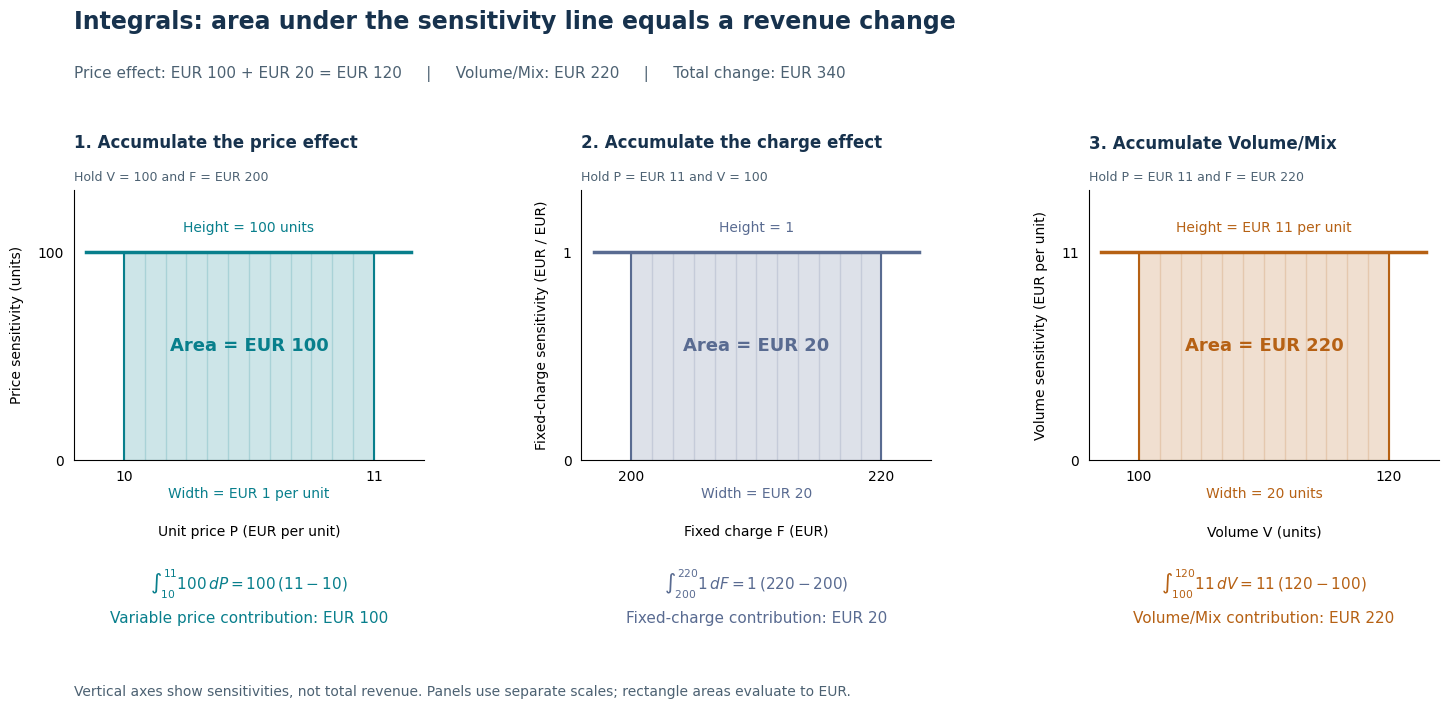

In [4]:
import matplotlib.pyplot as plt

p1, p2 = 10, 11
v1, v2 = 100, 120
f1, f2 = 200, 220
# Integrate a sensitivity, not the revenue function itself.
# The other inputs stay fixed along each comparison step.
panels = [
    dict(title='1. Accumulate the price effect', held='Hold V = 100 and F = EUR 200',
         x0=p1, x1=p2, height=v1, color='#087F8C',
         xlabel='Unit price P (EUR per unit)',
         ylabel='Price sensitivity (units)',
         height_label='Height = 100 units',
         width_label='Width = EUR 1 per unit',
         integral=r'$\int_{10}^{11}100\,dP=100\,(11-10)$',
         result='Variable price contribution: EUR 100'),
    dict(title='2. Accumulate the charge effect', held='Hold P = EUR 11 and V = 100',
         x0=f1, x1=f2, height=1, color='#596B91',
         xlabel='Fixed charge F (EUR)',
         ylabel='Fixed-charge sensitivity (EUR / EUR)',
         height_label='Height = 1',
         width_label='Width = EUR 20',
         integral=r'$\int_{200}^{220}1\,dF=1\,(220-200)$',
         result='Fixed-charge contribution: EUR 20'),
    dict(title='3. Accumulate Volume/Mix', held='Hold P = EUR 11 and F = EUR 220',
         x0=v1, x1=v2, height=p2, color='#B66114',
         xlabel='Volume V (units)',
         ylabel='Volume sensitivity (EUR per unit)',
         height_label='Height = EUR 11 per unit',
         width_label='Width = 20 units',
         integral=r'$\int_{100}^{120}11\,dV=11\,(120-100)$',
         result='Volume/Mix contribution: EUR 220'),
]
fig, axes = plt.subplots(1, 3, figsize=(15, 7.5), facecolor='white')
for ax, panel in zip(axes, panels):
    x0, x1, h = panel['x0'], panel['x1'], panel['height']
    width = x1-x0
    area = h*width
    # Sensitivity is constant along the step, hence a horizontal line.
    ax.plot([x0-0.15*width, x1+0.15*width], [h, h],
            color=panel['color'], linewidth=2.5)
    ax.fill_between([x0, x1], [h, h], 0,
                    color=panel['color'], alpha=0.20)
    ax.vlines([x0, x1], 0, h, color=panel['color'], linewidth=1.5)
    # Thin strips illustrate adding sensitivity * small input increments.
    # They partition the shaded area, rather than adding a second effect.
    for k in range(1, 12):
        x = x0 + width*k/12
        ax.vlines(x, 0, h, color=panel['color'], alpha=0.18, linewidth=1)
    ax.text((x0+x1)/2, h*0.55, f'Area = EUR {area:,.0f}',
            ha='center', va='center', color=panel['color'],
            fontsize=13, fontweight='bold')
    ax.text((x0+x1)/2, h*1.10, panel['height_label'],
            ha='center', fontsize=10, color=panel['color'])
    ax.text((x0+x1)/2, -0.13*h, panel['width_label'],
            ha='center', va='top', fontsize=10, color=panel['color'], clip_on=False)
    ax.set_xlim(x0-0.2*width, x1+0.2*width)
    ax.set_ylim(0, h*1.3)
    ax.set_xticks([x0, x1])
    ax.set_yticks([0, h])
    ax.set_xlabel(panel['xlabel'], labelpad=30, fontsize=10)
    ax.set_ylabel(panel['ylabel'], labelpad=10, fontsize=10)
    ax.set_title(panel['title'], loc='left', fontsize=12,
                 fontweight='bold', color='#17324D', pad=30)
    ax.text(0, 1.035, panel['held'], transform=ax.transAxes,
            fontsize=9, color='#4C6172')
    ax.text(0.5, -0.40, panel['integral']+'\n'+panel['result'],
            transform=ax.transAxes, ha='center', va='top',
            fontsize=11, color=panel['color'], linespacing=1.8)
    ax.tick_params(length=0, pad=7)
    for side in ['top', 'right']:
        ax.spines[side].set_visible(False)
fig.suptitle('Integrals: area under the sensitivity line equals a revenue change',
             x=0.065, y=0.96, ha='left', fontsize=17, fontweight='bold', color='#17324D')
fig.text(0.065, 0.87,
         'Price effect: EUR 100 + EUR 20 = EUR 120'
         '     |     Volume/Mix: EUR 220     |     Total change: EUR 340',
         fontsize=11, color='#4C6172')
fig.text(0.065, 0.045,
         'Vertical axes show sensitivities, not total revenue. Panels use separate scales; rectangle areas evaluate to EUR.',
         fontsize=10, color='#4C6172')
fig.subplots_adjust(left=0.065, right=0.975, top=0.72, bottom=0.36, wspace=0.45)
plt.show()


### 6.3. Evaluate the Three Integrals in the Example

Follow the same comparison sequence as Section 4. Coordinates below are $(P,V,F)$:

$$
(10,100,200)\longrightarrow(11,100,200)
\longrightarrow(11,100,220)\longrightarrow(11,120,220).
$$

**First, increase price from EUR 10 to EUR 11, holding quantity at 100 and the fixed charge at EUR 200.** The sensitivity to price stays at 100:

$$
\int_{10}^{11}100\,dP
=\left[100P\right]_{10}^{11}
=100(11-10)=100\text{ euros}.
$$

The brackets mean evaluate $100P$ at 11 and subtract its value at 10. Geometrically, this is a rectangle: 100 units multiplied by a EUR 1 per-unit price change. Revenue moves from EUR 1,200 to EUR 1,300.

**Second, increase the fixed charge from EUR 200 to EUR 220, keeping price at EUR 11 and quantity at 100.** Its sensitivity is 1:

$$
\int_{200}^{220}1\,dF
=\left[F\right]_{200}^{220}
=20\text{ euros}.
$$

Revenue reaches the intermediate scenario $S^*=1{,}320$. These two steps form the price effect: $100+20=120$ euros.

**Third, increase quantity from 100 to 120, keeping price at EUR 11 and the fixed charge at EUR 220.** The sensitivity to quantity is now 11:

$$
\int_{100}^{120}11\,dV
=\left[11V\right]_{100}^{120}
=11(120-100)=220\text{ euros}.
$$

This rectangle has height EUR 11 per unit and width 20 units. Revenue reaches the actual EUR 1,540. Combining the steps:

$$
\begin{aligned}
\Delta S
&=\underbrace{\int_{P_1}^{P_2}V_1\,dP+\int_{F_1}^{F_2}1\,dF}_{\text{Price Effect}}\\
&\quad+\underbrace{\int_{V_1}^{V_2}P_2\,dV}_{\text{Volume/Mix Effect}}\\
&=100+20+220=340\text{ euros}.
\end{aligned}
$$

The integrands are constant along their respective steps, so these integrals evaluate exactly to the multiplication formulas used in practice. Numerical integration is unnecessary. A decrease reverses the relevant limits and produces a negative contribution.



### 6.4. Why the Interaction Belongs to Volume/Mix

Define $\Delta P=P_2-P_1$, $\Delta V=V_2-V_1$, and $\Delta F=F_2-F_1$. Expanding the revenue change gives:

$$
\Delta S=V_1\Delta P+P_1\Delta V+\Delta P\Delta V+\Delta F.
$$

Using only the initial derivatives would give:

$$
V_1\Delta P+P_1\Delta V+\Delta F
=100+200+20=320\text{ euros}.
$$

This first-order approximation misses $\Delta P\Delta V=1\times20=20$ euros: the extra 20 units also earn the EUR 1 higher price. The standard methodology captures this interaction by valuing the quantity change at the current price:

$$
\text{Volume/Mix Effect}=P_2\Delta V
=P_1\Delta V+\Delta P\Delta V
=200+20=220\text{ euros}.
$$

If quantity were changed first at the old price, and price second at the new quantity, the split would instead be EUR 200 to volume and EUR 140 to price and fixed charges. Both sequences produce EUR 340 in total, but the price-first sequence matches the supplied convention.

**The total revenue change is independent of the comparison path; the allocation between effects depends on the path.** Calculus explains the chosen reporting convention. It does not establish a unique economic attribution or claim that actual commercial changes happened in this order.



## 7. Python Implementation and Expected Results

The Python analysis will prepare sales data, calculate weighted prices, classify relationships, calculate both effects, and verify that they reconcile to the observed revenue change. Tables and a revenue bridge chart will present the results. The worked example will also be reproduced using the calculus interpretation.

The data must use comparable periods, consistent currencies and units, and clear treatment of fixed charges. Missing values and zero quantities require explicit handling. The project explains revenue changes; conclusions about profitability or recovery of cost increases require additional cost data.
